# DevPilotAI: Benchmarking Software QA Architectures

A comparative benchmark of three approaches to repository-level question answering, evaluated on the same codebase (`psf/requests` v2.32.3), questions, and ground truth.

| # | Architecture | Indexing (Type 1) | QA (Type 2) | Updates (Type 3) |
| --- | --- | --- | --- | --- |
| 1 | **RAG** | Tree-sitter chunks, metadata, Chroma, and a file-to-chunk manifest | Top-k similarity search with a single LLM call | Delete, re-chunk, re-embed, and re-index the modified file |
| 2 | **RAG + Graph** | RAG index plus a file/class/function dependency graph | ReAct agent using `search_code`, `get_dependencies`, and `read_file` | Update RAG chunks and replace the file's graph nodes and edges |
| 3 | **RepoBrain** | Repository structure and code summaries with function, class, and line-range metadata | ReAct agent using `read_repo_brain` and `read_file` | Regenerate only the modified file's section |

## Evaluation Metrics

- **Type 1 — Indexing:** Total latency and phase breakdown.
- **Type 2 — QA:** LLM-as-judge, BLEU, ROUGE-L, perplexity, latency, token usage, and tool calls.
- **Type 3 — Updates:** Add, modify, or delete a function; compare incremental update latency against full re-indexing.

## Execution

Run the architectures in the order listed. Add your Groq API key in Cell 2 before running.



In [1]:
# install
%pip install -q tree-sitter tree-sitter-python chromadb sentence-transformers langchain-core langchain-groq langgraph networkx matplotlib pandas nltk rouge-score transformers

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.


In [2]:
#CONFIG
import os, re, sys, json, math, time, shutil, subprocess, zipfile, io, urllib.request, difflib, warnings
from pathlib import Path
from collections import defaultdict, deque
from dataclasses import dataclass, field

os.environ["USE_TF"] = "0"
os.environ["TRANSFORMERS_NO_TF"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")

GROQ_API_KEY = "api"
os.environ["GROQ_API_KEY"] = GROQ_API_KEY

# ---- models
QA_MODEL        = "openai/gpt-oss-120b"
QA_REASONING    = "low"
JUDGE_MODEL     = "openai/gpt-oss-120b"
EMBED_MODEL     = "sentence-transformers/all-MiniLM-L6-v2"
PPL_MODEL       = "distilgpt2"

# ---- repo
REPO_URL        = "https://github.com/psf/requests"
REPO_TAG        = "v2.32.3"
INDEX_DIRS      = ["src"]
INDEX_ROOT_FILES = ["README.md"]

# ---- chunking / retrieval
MAX_EMBED_CHARS = 2000
BIG_CLASS_CHARS = 4000
TOP_K           = 4
CTX_CHARS       = 2200

# ---- agents
RECURSION_LIMIT = 20
READ_MAX_LINES  = 120
BRAIN_MAX_INDEP = 600
# ---- Groq rate limit (tokens per minute)
TPM_LIMIT       = 6000
JUDGE_TPM_LIMIT = 10000

RESUME_FROM     = None

assert Path(".").exists()
print("config ok")

config ok


In [3]:
# repo download
WORK = Path("devpilot_work"); WORK.mkdir(exist_ok=True)
CACHE = WORK / "cache"
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
RUN_ID = time.strftime("%Y%m%d_%H%M%S")

def log(tag, msg): print(f"[{tag}] {msg}")

def fetch_repo(url, tag):
    name = url.rstrip("/").split("/")[-1]
    dest = CACHE / f"{name}-{tag}"
    if dest.exists():
        return dest
    CACHE.mkdir(parents=True, exist_ok=True)
    try:
        subprocess.run(["git", "clone", "--depth", "1", "--branch", tag, url, str(dest)], check=True, capture_output=True)
        log("OK", f"git clone {url}@{tag}")
    except Exception as e:
        log("WARN", f"git clone failed ({type(e).__name__}); trying github zip")
        shutil.rmtree(dest, ignore_errors=True)
        data = urllib.request.urlopen(f"{url}/archive/refs/tags/{tag}.zip", timeout=180).read()
        with zipfile.ZipFile(io.BytesIO(data)) as zf:
            top = zf.namelist()[0].split("/")[0]
            zf.extractall(CACHE)
        (CACHE / top).rename(dest)
        log("OK", "zip download")
    return dest

SRC = fetch_repo(REPO_URL, REPO_TAG)
REPO = WORK / f"repo_{RUN_ID}"
shutil.copytree(SRC, REPO, ignore=shutil.ignore_patterns(".git"))
log("OK", f"working copy: {REPO}")

[OK] git clone https://github.com/psf/requests@v2.32.3
[OK] working copy: devpilot_work/repo_20261023_183950


In [4]:
# tree-sitter parser: function / class / independent-code chunks + symbols
import tree_sitter_python as tspython
from tree_sitter import Language, Parser
_PARSER = Parser(Language(tspython.language()))

@dataclass
class Chunk:
    kind: str; name: str; file: str; start_line: int; end_line: int; text: str; id: str = ""
    def embed_text(self):
        return f"{self.file} | {self.kind} {self.name}\n{self.text}"[:MAX_EMBED_CHARS]
    def metadata(self):
        return {"file": self.file, "kind": self.kind, "name": self.name,
                "start_line": self.start_line, "end_line": self.end_line}

@dataclass
class Symbol:
    kind: str; name: str; qualname: str; start_line: int; end_line: int
    calls: list = field(default_factory=list); parent: str = None

@dataclass
class FileParse:
    path: str; n_lines: int = 0; language: str = "python"
    chunks: list = field(default_factory=list); symbols: list = field(default_factory=list)
    imports: list = field(default_factory=list); module_calls: list = field(default_factory=list)
    module_code: str = ""; module_ranges: list = field(default_factory=list); module_brain: str = ""

def _txt(src, n): return src[n.start_byte:n.end_byte].decode("utf-8", errors="replace")
def _span(n):
    s, e = n.start_point, n.end_point
    return s[0] + 1, (e[0] if (e[1] == 0 and e[0] > s[0]) else e[0] + 1)
def _name(n, src):
    x = n.child_by_field_name("name"); return _txt(src, x) if x is not None else "<anonymous>"

def _classify(node, src):
    inner = node
    if node.type == "decorated_definition":
        inner = next((c for c in node.named_children if c.type in ("function_definition", "class_definition")), None)
        if inner is None: return None
    if inner.type == "function_definition": return "function", _name(inner, src), inner
    if inner.type == "class_definition":    return "class", _name(inner, src), inner
    return None

def _is_doc_or_comment(n):
    return n.type == "comment" or (n.type == "expression_statement" and n.named_child_count == 1 and n.named_children[0].type == "string")

def _calls(node, src):
    out, stack = set(), [node]
    while stack:
        n = stack.pop()
        if n.type == "call":
            f = n.child_by_field_name("function")
            if f is not None:
                a = f.child_by_field_name("attribute")
                if a is not None: out.add(_txt(src, a))
                elif f.type == "identifier": out.add(_txt(src, f))
        stack.extend(n.children)
    return sorted(out)

def _imports(node, src):
    if node.type == "import_from_statement":
        m = node.child_by_field_name("module_name")
        base = _txt(src, m) if m is not None else ""
        if base and set(base) == {"."}:                     # "from . import utils, models"
            out = []
            for n in node.children_by_field_name("name"):
                nm = n.child_by_field_name("name") if n.type == "aliased_import" else n
                out.append(base + _txt(src, nm))
            return out
        return [base] if base else []
    out = []                                                 # "import a.b"
    for c in node.named_children:
        if c.type == "dotted_name": out.append(_txt(src, c))
        elif c.type == "aliased_import":
            n = c.child_by_field_name("name")
            if n is not None: out.append(_txt(src, n))
    return out

def parse_file(root, rel):
    src = (Path(root) / rel).read_bytes()
    fp = _parse_py(rel, src) if rel.endswith(".py") else _parse_text(rel, src)
    fp.chunks.sort(key=lambda c: c.start_line)
    for i, c in enumerate(fp.chunks):
        c.id = f"{rel}::{i}::{c.kind}::{c.name}"
    return fp

def _parse_text(rel, src, window=40):
    lines = src.decode("utf-8", errors="replace").splitlines()
    fp = FileParse(path=rel, n_lines=len(lines), language="text")
    for s in range(0, len(lines), window):
        body = "\n".join(lines[s:s + window])
        if body.strip():
            fp.chunks.append(Chunk("text", f"{rel}:{s+1}", rel, s + 1, min(s + window, len(lines)), body))
    return fp

def _parse_py(rel, src):
    root = _PARSER.parse(src).root_node
    fp = FileParse(path=rel, n_lines=src.count(b"\n") + 1)
    runs, cur, mod_calls = [], [], set()
    for node in root.named_children:
        info = _classify(node, src)
        if info is None:                                      # independent code (imports, constants, if __name__ ...)
            cur.append(node)
            if node.type in ("import_statement", "import_from_statement", "future_import_statement"):
                fp.imports.extend(_imports(node, src))
            mod_calls.update(_calls(node, src)); continue
        if cur: runs.append(cur); cur = []
        kind, name, inner = info
        s, e = _span(node)
        if kind == "function":
            fp.chunks.append(Chunk("function", name, rel, s, e, _txt(src, node)))
            fp.symbols.append(Symbol("function", name, name, s, e, _calls(inner, src)))
        else:
            _add_class(fp, node, inner, name, src)
    if cur: runs.append(cur)
    fp.module_calls = sorted(mod_calls)
    if runs:
        segs = []
        for run in runs:
            a, b = run[0], run[-1]
            segs.append((a.start_point[0] + 1, _span(b)[1], src[a.start_byte:b.end_byte].decode("utf-8", errors="replace")))
        fp.module_ranges = [(a, b) for a, b, _ in segs]
        fp.module_code = "\n...\n".join(t for _, _, t in segs)
        fp.module_brain = "\n".join(x for x in ("\n".join(_txt(src, n) for n in run if not _is_doc_or_comment(n)) for run in runs) if x)
        fp.chunks.append(Chunk("module_code", "<module>", rel, segs[0][0], segs[-1][1], fp.module_code))
    return fp

def _add_class(fp, node, inner, cname, src):
    s, e = _span(node)
    methods = []
    body = inner.child_by_field_name("body")
    if body is not None:
        for c in body.named_children:
            info = _classify(c, src)
            if info and info[0] == "function": methods.append((c, info[1], info[2]))
    fp.symbols.append(Symbol("class", cname, cname, s, e, []))
    for outer, mname, minner in methods:
        ms, me = _span(outer)
        fp.symbols.append(Symbol("method", mname, f"{cname}.{mname}", ms, me, _calls(minner, src), parent=cname))
    text = _txt(src, node)
    if len(text) <= BIG_CLASS_CHARS or not methods:
        fp.chunks.append(Chunk("class", cname, fp.path, s, e, text)); return
    first = methods[0][0]
    fp.chunks.append(Chunk("class_header", cname, fp.path, s, max(s, first.start_point[0]),
                           src[node.start_byte:first.start_byte].decode("utf-8", errors="replace")))
    for outer, mname, _ in methods:
        ms, me = _span(outer)
        fp.chunks.append(Chunk("method", f"{cname}.{mname}", fp.path, ms, me, _txt(src, outer)))

def list_files(root):
    root, out = Path(root), set()
    for d in INDEX_DIRS:
        for p in (root / d).rglob("*.py"):
            if "__pycache__" not in p.parts: out.add(p.relative_to(root).as_posix())
    for f in INDEX_ROOT_FILES:
        if (root / f).exists(): out.add(f)
    return sorted(out)

class PhaseTimer:
    def __init__(self): self.phases, self._t0 = {}, time.perf_counter()
    def phase(self, name):
        timer = self
        class _C:
            def __enter__(s): s.t = time.perf_counter()
            def __exit__(s, *a): timer.add(name, time.perf_counter() - s.t)
        return _C()
    def add(self, name, secs): self.phases[name] = self.phases.get(name, 0.0) + secs
    @property
    def total(self): return time.perf_counter() - self._t0

_files = list_files(REPO)
_parses = [parse_file(REPO, f) for f in _files]
log("OK", f"{len(_files)} files, {sum(len(p.chunks) for p in _parses)} chunks, {sum(len(p.symbols) for p in _parses)} symbols")

[OK] 19 files, 243 chunks, 274 symbols


In [5]:
#local Chroma vector store + manifest
import chromadb
from chromadb.config import Settings

class RagStore:
    BATCH = 500
    def __init__(self, db_dir, embedder, name):
        self.db_dir = Path(db_dir); self.db_dir.mkdir(parents=True, exist_ok=True)
        self.embedder = embedder
        client = chromadb.PersistentClient(path=str(self.db_dir), settings=Settings(anonymized_telemetry=False))
        self.col = client.get_or_create_collection(name, metadata={"hnsw:space": "cosine"})
        self.manifest = {}

    def add_parses(self, parses):
        chunks = [c for p in parses for c in p.chunks]
        t_embed = t_store = 0.0
        if chunks:
            t = time.perf_counter()
            embs = self.embedder.embed([c.embed_text() for c in chunks])
            t_embed = time.perf_counter() - t
            t = time.perf_counter()
            for i in range(0, len(chunks), self.BATCH):
                part = chunks[i:i + self.BATCH]
                self.col.add(ids=[c.id for c in part], embeddings=embs[i:i + self.BATCH],
                             documents=[c.text for c in part], metadatas=[c.metadata() for c in part])
            t_store = time.perf_counter() - t
        t = time.perf_counter()
        for p in parses: self.manifest[p.path] = [c.id for c in p.chunks]
        (self.db_dir / "manifest.json").write_text(json.dumps(self.manifest))
        return {"embed": t_embed, "store": t_store + time.perf_counter() - t}

    def remove_file(self, path):
        ids = self.manifest.pop(path, [])
        if ids: self.col.delete(ids=ids)
        (self.db_dir / "manifest.json").write_text(json.dumps(self.manifest))
        return len(ids)

    def query(self, text, k):
        n = self.col.count()
        if n == 0: return []
        r = self.col.query(query_embeddings=self.embedder.embed([text]), n_results=min(k, n))
        return [{**m, "text": d, "score": 1 - dist} for d, m, dist in zip(r["documents"][0], r["metadatas"][0], r["distances"][0])]

    def count(self): return self.col.count()
    def all_ids(self): return set(self.col.get(include=[])["ids"])

In [6]:
# dependency graph: file -> class -> function, imports + calls
import networkx as nx

def resolve_import(importer, module, files):
    """'.utils' / '..pkg.mod' / 'requests.utils' -> repo ki file path (ya None)"""
    d = os.path.dirname(importer)
    if module.startswith("."):
        dots = len(module) - len(module.lstrip("."))
        base = d
        for _ in range(dots - 1): base = os.path.dirname(base)
        rest = module.lstrip(".").replace(".", "/")
        stem = (base + "/" + rest) if base and rest else (base or rest)
        return next((c for c in (stem + ".py", stem + "/__init__.py") if c in files), None)
    stem = module.replace(".", "/")
    for f in sorted(files):
        if f == stem + ".py" or f.endswith("/" + stem + ".py") or f.endswith("/" + stem + "/__init__.py"):
            return f
    return None

class CodeGraph:
    """Nodes: file / class / function / method.  Edges: contains, imports (file->file), calls (name-based, approximate).
    Incremental: add_file() / remove_file() sirf us file ke nodes + usse judi edges badalte hain."""
    def __init__(self):
        self.g = nx.DiGraph()
        self.parses, self.raw_imports = {}, {}
        self.by_name = defaultdict(set)            # symbol name -> node ids
        self.callers_by_name = defaultdict(set)    # callee name -> caller node ids
        self._reg = {}

    def add_file(self, p):
        self.remove_file(p.path)
        self.parses[p.path] = p
        fid = f"file:{p.path}"
        self.g.add_node(fid, kind="file", path=p.path, name=p.path)
        reg = {"nodes": [fid], "keys": [], "calls": []}
        for s in p.symbols:
            nid = f"{s.kind}:{p.path}::{s.qualname}"
            self.g.add_node(nid, kind=s.kind, path=p.path, name=s.qualname, start=s.start_line, end=s.end_line)
            parent = f"class:{p.path}::{s.parent}" if s.parent else fid
            self.g.add_edge(parent, nid, rel="contains")
            reg["nodes"].append(nid)
            for key in {s.name, s.qualname}:
                self.by_name[key].add(nid); reg["keys"].append((key, nid))
        srcs = [(f"{s.kind}:{p.path}::{s.qualname}", s.calls) for s in p.symbols if s.kind != "class"] + [(fid, p.module_calls)]
        for src, calls in srcs:                                      # outgoing call edges
            for name in calls:
                self.callers_by_name[name].add(src); reg["calls"].append((src, name))
                for tgt in self.by_name.get(name, ()):
                    if tgt != src: self.g.add_edge(src, tgt, rel="calls")
        for s in p.symbols:                                          # incoming call edges (baaki files jo is naam ko call karti hain)
            nid = f"{s.kind}:{p.path}::{s.qualname}"
            for src in self.callers_by_name.get(s.name, ()):
                if src != nid: self.g.add_edge(src, nid, rel="calls")
        files = set(self.parses)                                     # imports: outgoing + incoming
        self.raw_imports[p.path] = p.imports
        for q, mods in self.raw_imports.items():
            for m in mods:
                r = resolve_import(q, m, files)
                if r and r != q and (q == p.path or r == p.path):
                    self.g.add_edge(f"file:{q}", f"file:{r}", rel="imports")
        self._reg[p.path] = reg

    def remove_file(self, path):
        if path not in self.parses: return
        reg = self._reg.pop(path)
        for key, nid in reg["keys"]: self.by_name[key].discard(nid)
        for src, name in reg["calls"]: self.callers_by_name[name].discard(src)
        self.g.remove_nodes_from(reg["nodes"])                       # incident edges apne aap hat jaate hain
        del self.parses[path]; del self.raw_imports[path]

    def signature(self):
        return (frozenset(self.g.nodes), frozenset((u, v, d["rel"]) for u, v, d in self.g.edges(data=True)))

    def stats(self):
        rels = [d["rel"] for _, _, d in self.g.edges(data=True)]
        return {"nodes": self.g.number_of_nodes(), "contains": rels.count("contains"),
                "imports": rels.count("imports"), "calls": rels.count("calls")}

    # ---------- queries (graph tool isi ko call karta hai)
    @staticmethod
    def _cap(items, n=25):
        items = list(items)
        return "none" if not items else ", ".join(items[:n]) + (f" ... (+{len(items)-n} more)" if len(items) > n else "")

    def _label(self, n):
        d = self.g.nodes[n]
        if d["kind"] == "file": return d["path"]
        return f"{d['path']}:{d['name']}" + (f" (L{d['start']}-{d['end']})" if "start" in d else "")

    def query(self, name):
        name = name.strip()
        fid = f"file:{name}" if f"file:{name}" in self.g else next(
            (n for n in self.g if n.startswith("file:") and n.endswith("/" + name)), None)
        if fid: return self._file_view(fid)
        nodes = [n for n in self.by_name.get(name, ())]
        if not nodes:
            close = difflib.get_close_matches(name, list(self.by_name), n=5, cutoff=0.6)
            return f"No file/function/class named '{name}' in graph." + (f" Did you mean: {', '.join(close)}?" if close else "")
        return "\n\n".join(self._symbol_view(n) for n in sorted(nodes)[:6])

    def _file_view(self, fid):
        succ = lambda rel: sorted(self._label(v) for _, v, d in self.g.out_edges(fid, data=True) if d["rel"] == rel)
        pred = sorted(self._label(u) for u, _, d in self.g.in_edges(fid, data=True) if d["rel"] == "imports")
        return (f"FILE {self.g.nodes[fid]['path']}\ndefines: {self._cap(succ('contains'))}\n"
                f"imports (in repo): {self._cap(succ('imports'))}\nimported by: {self._cap(pred)}")

    def _symbol_view(self, nid):
        d = self.g.nodes[nid]
        lines = [f"{d['kind'].upper()} {d['name']} in {d['path']} (L{d['start']}-{d['end']})"]
        if d["kind"] == "class":
            lines.append("methods: " + self._cap(sorted(self._label(v) for _, v, e in self.g.out_edges(nid, data=True) if e["rel"] == "contains")))
        out = sorted(self._label(v) for _, v, e in self.g.out_edges(nid, data=True) if e["rel"] == "calls")
        inc = sorted(self._label(u) if self.g.nodes[u]["kind"] != "file" else f"{self.g.nodes[u]['path']} (module-level)"
                     for u, _, e in self.g.in_edges(nid, data=True) if e["rel"] == "calls")
        lines.append("calls (defined in repo): " + self._cap(out))
        lines.append("called/used by: " + self._cap(inc))
        return "\n".join(lines)

In [7]:
#RepoBrain: folder structure
def render_tree(paths):
    tree = {}
    for p in paths:
        node = tree
        for part in p.split("/"): node = node.setdefault(part, {})
    lines = []
    def walk(n, depth):
        for k in sorted(n):
            lines.append("  " * depth + k + ("/" if n[k] else "")); walk(n[k], depth + 1)
    walk(tree, 0)
    return "\n".join(lines)

def render_section(p):
    out = [f"### {p.path} ({p.n_lines} lines)"]
    if p.language == "text":
        return "\n".join(out + ["(text file: use read_file)"])
    if p.module_brain:
        code = p.module_brain
        if BRAIN_MAX_INDEP and len(code) > BRAIN_MAX_INDEP:
            code = code[:BRAIN_MAX_INDEP].rstrip() + "\n... [truncated, use read_file for the rest]"
        out.append("independent code (lines " + ", ".join(f"{a}-{b}" for a, b in p.module_ranges) + "; comments/docstrings omitted):\n" + code)
    for c in (s for s in p.symbols if s.kind == "class"):
        ms = "; ".join(f"{m.name} {m.start_line}-{m.end_line}" for m in p.symbols if m.parent == c.qualname)
        out.append(f"class {c.name} ({c.start_line}-{c.end_line})" + (f" methods: {ms}" if ms else ""))
    fns = "; ".join(f"{f.name} ({f.start_line}-{f.end_line})" for f in p.symbols if f.kind == "function")
    if fns: out.append("functions: " + fns)
    return "\n".join(out)

class RepoBrainIndex:
    def __init__(self, path): self.path, self.sections = Path(path), {}
    def write(self):
        paths = sorted(self.sections)
        body = "\n\n".join(self.sections[p] for p in paths)
        self.path.write_text(f"# REPO BRAIN\n\n## Folder structure\n{render_tree(paths)}\n\n## Files\n\n{body}\n", encoding="utf-8")

_b = RepoBrainIndex(WORK / "_probe_brain.md"); _b.sections = {p.path: render_section(p) for p in _parses}; _b.write()
_n = _b.path.stat().st_size
log("OK", f"repo brain probe: {_n} chars (~{_n // 4} tokens)")

[OK] repo brain probe: 16468 chars (~4117 tokens)


In [8]:
#TPM guard + tools + agent runner
from langchain_core.callbacks import BaseCallbackHandler
from langchain_core.tools import tool
from langchain_core.messages import AIMessage

class TPMGuard(BaseCallbackHandler):
    def __init__(self, limit, label="QA"):
        self.limit, self.label, self.log, self.wait_s, self._est = limit, label, deque(), 0.0, 0

    def _expire(self, now):
        while self.log and now - self.log[0][0] > 60: self.log.popleft()

    def on_chat_model_start(self, serialized, messages, **kwargs):
        chars = sum(len(m.content if isinstance(m.content, str) else str(m.content)) for batch in messages for m in batch)
        self._est = int(chars / 3.2) + 900
        warned, waited = False, 0.0
        while True:
            now = time.time(); self._expire(now)
            used = sum(t for _, t in self.log)
            if used == 0 or used + self._est <= self.limit: break
            d = min(max(self.log[0][0] + 60 - now + 0.25, 0.25), 15)
            if not warned:
                log("TPM", f"{self.label}: ~{used}+{self._est} > {self.limit}; should wait (wont be counted in latency)"); warned = True
            time.sleep(d); waited += d
        self.wait_s += waited

    def on_llm_end(self, response, **kwargs):
        tokens = 0
        for gens in response.generations:
            for g in gens:
                um = getattr(getattr(g, "message", None), "usage_metadata", None)
                if um: tokens += um.get("total_tokens", 0)
        self.log.append((time.time(), tokens or self._est))

def make_read_file_tool(root):
    root = Path(root).resolve()
    @tool
    def read_file(path: str, start_line: int = 1, end_line: int = 0) -> str:
        """Read a repository file. `path` is relative to the repo root (e.g. 'src/requests/api.py').
        Optionally give start_line / end_line (1-based, inclusive). If end_line is 0, up to 120 lines from start_line are returned."""
        p = (root / path).resolve()
        if root != p and root not in p.parents: return "Error: path is outside the repository."
        if not p.is_file(): return f"Error: file not found: {path}. Use the exact path from the repo brain / search results."
        lines = p.read_text(encoding="utf-8", errors="replace").splitlines()
        s = max(1, start_line)
        e = min(end_line if end_line > 0 else s + READ_MAX_LINES - 1, len(lines), s + READ_MAX_LINES - 1)
        body = "\n".join(f"{i}: {lines[i-1]}" for i in range(s, e + 1))
        return f"{path} [lines {s}-{e} of {len(lines)}]\n{body}"
    return read_file

def make_search_tool(store, k):
    @tool
    def search_code(query: str) -> str:
        """Semantic search over the indexed repository. Returns the top matching code chunks with file path,
        symbol name, line range and a snippet. Use read_file afterwards if you need more context."""
        hits = store.query(query, k)
        if not hits: return "No results."
        return "\n\n".join(
            f"[{i}] {h['file']} | {h['kind']} {h['name']} | lines {h['start_line']}-{h['end_line']}\n"
            f"{h['text'][:500]}{'...' if len(h['text']) > 500 else ''}" for i, h in enumerate(hits, 1))
    return search_code

def make_graph_tool(graph):
    @tool
    def get_dependencies(name: str) -> str:
        """Dependency graph lookup. `name` = file path (e.g. 'api.py' or 'src/requests/api.py'), function, class or 'Class.method'.
        Returns what it defines / imports / calls and what imports / calls it (name-based, so common names can be ambiguous)."""
        return graph.query(name)
    return get_dependencies

def make_brain_tool(brain_index, state):
    @tool
    def read_repo_brain() -> str:
        """Returns the whole repo brain: folder structure and, for every file, its independent code, classes (with methods)
        and functions with line ranges. Takes no arguments. Call it ONCE, then use read_file for details."""
        if state["calls"] >= 1:
            return "You already received the repo brain earlier in this conversation. Do NOT call this tool again; use read_file."
        state["calls"] += 1
        return brain_index.path.read_text(encoding="utf-8")
    return read_repo_brain

SYS_BASE = ("You are an expert Python engineer answering questions about the source code of the `requests` library. "
            "Base your answer ONLY on what the tools returned; never guess. Answer concisely (under ~120 words), naming files, "
            "functions and line numbers where useful. If the evidence is insufficient, say what is missing.")
TOOL_RULE = ("\nCall ONLY the tools listed here, using their exact names (no prefixes such as 'repo_browser.'): {names}.")

def usage_of(msgs):
    i = o = 0
    for m in msgs:
        um = getattr(m, "usage_metadata", None)
        if um: i += um.get("input_tokens", 0); o += um.get("output_tokens", 0)
    return i, o

def as_text(c):
    return c if isinstance(c, str) else "".join(x if isinstance(x, str) else x.get("text", "") for x in c) if isinstance(c, list) else str(c)

def run_agent(agent, question, guard, tool_names):
    from langgraph.errors import GraphRecursionError
    w0, t0, retries, err, msgs = guard.wait_s, time.perf_counter(), 0, None, []
    prompt = question
    for attempt in range(3):
        try:
            res = agent.invoke({"messages": [("user", prompt)]}, config={"recursion_limit": RECURSION_LIMIT})
            msgs, err = res["messages"], None; break
        except GraphRecursionError:
            err = "recursion_limit"; break
        except Exception as e:
            s = str(e)
            if ("tool_use_failed" in s or "tool call validation failed" in s.lower()) and attempt < 2:
                retries += 1
                prompt = question + f"\n\n(Reminder: call ONLY these tools by exact name: {', '.join(tool_names)}.)"
                continue
            err = f"{type(e).__name__}: {s}"[:250]; break
    wall = time.perf_counter() - t0; wait = guard.wait_s - w0
    ai = [m for m in msgs if isinstance(m, AIMessage)]
    trace = [tc["name"] for m in ai for tc in (m.tool_calls or [])]
    final = next((as_text(m.content) for m in reversed(ai) if as_text(m.content).strip() and not m.tool_calls), "")
    tin, tout = usage_of(ai)
    return dict(answer=final, latency_s=wall - wait, wall_s=wall, wait_s=wait, llm_calls=len(ai), tool_calls=len(trace),
                tokens_in=tin, tokens_out=tout, retries=retries, error=err, tools_used=trace)

In [9]:
#models: embedder (HF, local), Groq LLMs, judge, BLEU / ROUGE-L / perplexity
from langchain_groq import ChatGroq
from sentence_transformers import SentenceTransformer
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from rouge_score import rouge_scorer
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

if "PASTE_YOUR" in GROQ_API_KEY: raise ValueError("Cell 2 me GROQ_API_KEY paste karo")

class Embedder:
    def __init__(self, name):
        self.model = SentenceTransformer(name, device="cpu")
    def embed(self, texts):
        return self.model.encode(texts, batch_size=32, normalize_embeddings=True, show_progress_bar=False).tolist()

t0 = time.perf_counter()
embedder = Embedder(EMBED_MODEL); embedder.embed(["warmup"])
log("OK", f"embedding model loaded in {time.perf_counter()-t0:.1f}s (shared, Type 1 me count nahi hota)")

def make_chat(model, guard, effort=None):
    kw = dict(model=model, temperature=0, max_retries=3, callbacks=[guard])
    if effort:
        try: return ChatGroq(**kw, reasoning_effort=effort)
        except Exception: return ChatGroq(**kw, model_kwargs={"reasoning_effort": effort})
    return ChatGroq(**kw)

qa_guard, judge_guard = TPMGuard(TPM_LIMIT, "QA"), TPMGuard(JUDGE_TPM_LIMIT, "judge")
qa_llm    = make_chat(QA_MODEL, qa_guard, QA_REASONING)
judge_llm = make_chat(JUDGE_MODEL, judge_guard)

# ---------- LLM-as-judge
JUDGE_PROMPT = """You are a strict grader. Compare the CANDIDATE answer with the GROUND TRUTH for the question.
Score 0-10: 10 = all key facts of the ground truth present and correct; 5 = roughly half the facts or partly wrong;
0 = wrong, empty, or says it cannot answer. Penalize wrong or missing facts (e.g. wrong counts, missing list items). Do not reward extra detail.

QUESTION: {q}
GROUND TRUTH: {t}
CANDIDATE: {a}

Reply with JSON only: {{"score": <integer 0-10>, "reason": "<one short sentence>"}}"""

def llm_judge(q, truth, answer):
    if not answer.strip(): return 0.0, "empty answer"
    for _ in range(2):
        try:
            raw = as_text(judge_llm.invoke(JUDGE_PROMPT.format(q=q, t=truth, a=answer[:3000])).content)
            d = json.loads(re.search(r"\{.*\}", raw, re.S).group())
            return max(0, min(10, int(d["score"]))) / 10, str(d.get("reason", ""))[:200]
        except Exception as e:
            last = f"{type(e).__name__}"
    return float("nan"), f"judge failed: {last}"

# ---------- BLEU / ROUGE-L / perplexity
_smooth = SmoothingFunction().method1
_rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
def _tok(s): return re.findall(r"\w+", s.lower())
def bleu(ref, hyp):
    h = _tok(hyp)
    return sentence_bleu([_tok(ref)], h, smoothing_function=_smooth) if h else 0.0
def rouge_l(ref, hyp): return _rouge.score(ref, hyp)["rougeL"].fmeasure if hyp.strip() else 0.0

ppl_tok = AutoTokenizer.from_pretrained(PPL_MODEL)
ppl_model = AutoModelForCausalLM.from_pretrained(PPL_MODEL).eval()
def perplexity(text):
    if not text.strip(): return float("nan")
    ids = ppl_tok(text, return_tensors="pt", truncation=True, max_length=256).input_ids
    if ids.shape[1] < 2: return float("nan")
    with torch.no_grad(): loss = ppl_model(ids, labels=ids).loss
    return math.exp(loss.item())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [10]:
#3 architectures (index / ask / update / verify)
import pandas as pd

def _ask_result(**kw):
    base = dict(answer="", latency_s=0.0, wall_s=0.0, wait_s=0.0, llm_calls=0, tool_calls=0, tokens_in=0, tokens_out=0,
                retries=0, error=None, tools_used=[])
    base.update(kw); return base

class SimpleRAG:
    """Architecture 1: RAG. retrieve top-k -> prompt ->LLM call."""
    name = "RAG"
    key = "rag"

    def _index_extra(self, parses, t): pass
    def _on_remove(self, path, t): pass
    def _on_add(self, parses, t): pass

    def index(self, root):
        self.root, self._agent, t = Path(root), None, PhaseTimer()
        with t.phase("init_db"):
            self.store = RagStore(WORK / f"chroma_{RUN_ID}_{self.key}", embedder, f"{self.key}_{RUN_ID}")
        with t.phase("scan"): files = list_files(self.root)
        with t.phase("parse"): parses = [parse_file(self.root, f) for f in files]
        tm = self.store.add_parses(parses); t.add("embed", tm["embed"]); t.add("store", tm["store"])
        self._index_extra(parses, t)
        return dict(total_s=t.total, **{f"ph_{k}": v for k, v in t.phases.items()}, n_files=len(files), n_chunks=self.store.count())

    def update(self, path):
        t, exists = PhaseTimer(), (self.root / path).exists()
        with t.phase("remove_old"): removed = self.store.remove_file(path)
        self._on_remove(path, t)
        added = 0
        if exists:
            with t.phase("parse"): p = parse_file(self.root, path)
            tm = self.store.add_parses([p]); t.add("embed", tm["embed"]); t.add("store", tm["store"])
            self._on_add([p], t); added = len(p.chunks)
        return dict(total_s=t.total, **{f"ph_{k}": v for k, v in t.phases.items()}, chunks_removed=removed, chunks_added=added)

    def verify(self):
        files = list_files(self.root)
        fresh = {c.id for f in files for c in parse_file(self.root, f).chunks}
        return self.store.all_ids() == fresh and set(self.store.manifest) == set(files)

    def ask(self, q):
        w0, t0 = qa_guard.wait_s, time.perf_counter()
        hits = self.store.query(q, TOP_K)
        ctx = "\n\n".join(f"[{i}] {h['file']} | {h['kind']} {h['name']} | lines {h['start_line']}-{h['end_line']}\n{h['text'][:CTX_CHARS]}"
                          for i, h in enumerate(hits, 1))
        msgs = [("system", SYS_BASE + " You only see the retrieved context below; if it is not enough, say so."),
                ("user", f"Context:\n{ctx}\n\nQuestion: {q}")]
        text, err, tin, tout = "", None, 0, 0
        try:
            r = qa_llm.invoke(msgs); text = as_text(r.content); tin, tout = usage_of([r])
        except Exception as e: err = f"{type(e).__name__}: {e}"[:250]
        wall = time.perf_counter() - t0; wait = qa_guard.wait_s - w0
        return _ask_result(answer=text, latency_s=wall - wait, wall_s=wall, wait_s=wait, llm_calls=1, tokens_in=tin,
                           tokens_out=tout, error=err)

class _AgentMixin:
    def _tools(self): raise NotImplementedError
    def _prompt(self): raise NotImplementedError
    def _get_agent(self):
        if self._agent is None:
            from langgraph.prebuilt import create_react_agent
            self._tool_objs = self._tools()
            try:
                self._agent = create_react_agent(qa_llm, self._tool_objs, prompt=self._prompt())
            except TypeError:
                self._agent = create_react_agent(qa_llm, self._tool_objs, state_modifier=self._prompt())
        return self._agent
    def ask(self, q):
        agent = self._get_agent()
        self._reset_state()
        return run_agent(agent, q, qa_guard, [t.name for t in self._tool_objs])
    def _reset_state(self): pass

class GraphRAG(_AgentMixin, SimpleRAG):
    """Architecture 2: RAG index + dependency graph. Tools: search_code, get_dependencies, read_file."""
    name = "RAG+Graph"
    key = "graph"
    def _index_extra(self, parses, t):
        with t.phase("graph"):
            self.graph = CodeGraph()
            for p in parses: self.graph.add_file(p)
    def _on_remove(self, path, t):
        with t.phase("graph"): self.graph.remove_file(path)
    def _on_add(self, parses, t):
        with t.phase("graph"):
            for p in parses: self.graph.add_file(p)
    def verify(self):
        fresh = CodeGraph()
        for f in list_files(self.root): fresh.add_file(parse_file(self.root, f))
        return super().verify() and fresh.signature() == self.graph.signature()
    def _tools(self): return [make_search_tool(self.store, TOP_K), make_graph_tool(self.graph), make_read_file_tool(self.root)]
    def _prompt(self):
        return (SYS_BASE + "\nTools: `search_code` (semantic search), `get_dependencies` (who defines/imports/calls a file, "
                "function or class) and `read_file`. Use the graph for relationship questions, search/read for details."
                + TOOL_RULE.format(names="search_code, get_dependencies, read_file"))

class RepoBrain(_AgentMixin):
    """Architecture 3: RepoBrain. Tools: read_repo_brain (no query, poora brain), read_file."""
    name = "RepoBrain"
    key = "brain"
    def index(self, root):
        self.root, self._agent, t = Path(root), None, PhaseTimer()
        self.brain = RepoBrainIndex(WORK / f"REPO_BRAIN_{RUN_ID}.md")
        with t.phase("scan"): files = list_files(self.root)
        with t.phase("parse"): parses = [parse_file(self.root, f) for f in files]
        with t.phase("render"): self.brain.sections = {p.path: render_section(p) for p in parses}
        with t.phase("write"): self.brain.write()
        return dict(total_s=t.total, **{f"ph_{k}": v for k, v in t.phases.items()}, n_files=len(files),
                    n_chunks=sum(len(p.chunks) for p in parses))
    def update(self, path):
        t, exists = PhaseTimer(), (self.root / path).exists()
        with t.phase("remove_old"): had = self.brain.sections.pop(path, None) is not None
        if exists:
            with t.phase("parse"): p = parse_file(self.root, path)
            with t.phase("render"): self.brain.sections[path] = render_section(p)
        with t.phase("write"): self.brain.write()
        return dict(total_s=t.total, **{f"ph_{k}": v for k, v in t.phases.items()}, chunks_removed=int(had), chunks_added=int(exists))
    def verify(self):
        return {f: render_section(parse_file(self.root, f)) for f in list_files(self.root)} == self.brain.sections
    def _reset_state(self): self._brain_state["calls"] = 0
    def _tools(self):
        self._brain_state = {"calls": 0}
        return [make_brain_tool(self.brain, self._brain_state), make_read_file_tool(self.root)]
    def _prompt(self):
        return (SYS_BASE + "\nTools: `read_repo_brain` (no arguments: folder structure + every file's independent code, classes and "
                "functions with line ranges) and `read_file` (read a file / line range). Call read_repo_brain once, decide which files "
                "matter, then read them." + TOOL_RULE.format(names="read_repo_brain, read_file"))

In [11]:
# dataset
DATASET = [
 {"id": "q01", "category": "lookup", "question": "Which file defines the Session class, and which base class does it inherit from?",
  "truth": "The Session class is defined in src/requests/sessions.py and it inherits from SessionRedirectMixin."},
 {"id": "q02", "category": "lookup", "question": "When I call requests.get(url), which function does it delegate to and with which HTTP method string?",
  "truth": "requests.get (in api.py) delegates to the request() function, calling request(\"get\", url, params=params, **kwargs)."},
 {"id": "q03", "category": "lookup", "question": "What does the api.request function do internally to send the HTTP request?",
  "truth": "api.request opens a Session with `with sessions.Session() as session:` and returns session.request(method=method, url=url, **kwargs)."},
 {"id": "q04", "category": "lookup", "question": "What string does utils.default_user_agent return by default?",
  "truth": "default_user_agent returns f\"{name}/{__version__}\" with name defaulting to \"python-requests\", i.e. \"python-requests/<version>\"."},
 {"id": "q05", "category": "lookup", "question": "In adapters.py, what are the values of DEFAULT_POOLSIZE and DEFAULT_RETRIES?",
  "truth": "DEFAULT_POOLSIZE is 10 and DEFAULT_RETRIES is 0."},
 {"id": "q06", "category": "lookup", "question": "Which exception does Response.raise_for_status raise for 4xx/5xx responses, and which module defines that exception class?",
  "truth": "raise_for_status (in models.py) raises HTTPError, which is defined in exceptions.py."},
 {"id": "q07", "category": "lookup", "question": "What are the base classes of ConnectTimeout and ReadTimeout in exceptions.py?",
  "truth": "ConnectTimeout inherits from ConnectionError and Timeout; ReadTimeout inherits from Timeout."},
 {"id": "q08", "category": "lookup", "question": "Which classes in auth.py implement authentication, and which class does HTTPProxyAuth inherit from?",
  "truth": "auth.py defines AuthBase (base class), HTTPBasicAuth, HTTPProxyAuth and HTTPDigestAuth. HTTPProxyAuth inherits from HTTPBasicAuth."},
 {"id": "q09", "category": "global", "question": "List all the Python modules (files) inside the src/requests package.",
  "truth": "The src/requests package has 18 modules: __init__.py, __version__.py, _internal_utils.py, adapters.py, api.py, auth.py, certs.py, compat.py, cookies.py, exceptions.py, help.py, hooks.py, models.py, packages.py, sessions.py, status_codes.py, structures.py, utils.py."},
 {"id": "q10", "category": "global", "question": "How many top-level functions are defined in api.py, and what are their names?",
  "truth": "api.py defines 8 top-level functions: request, get, options, head, post, put, patch and delete."},
 {"id": "q11", "category": "global", "question": "How many classes are defined in exceptions.py?",
  "truth": "exceptions.py defines 25 classes: 22 exception classes (RequestException and its subclasses) plus 3 warning classes (RequestsWarning, FileModeWarning, RequestsDependencyWarning)."},
 {"id": "q12", "category": "relationship", "question": "Which modules of the requests package import from the exceptions module?",
  "truth": "__init__.py, adapters.py, models.py, sessions.py and utils.py import from .exceptions."},
 {"id": "q13", "category": "relationship", "question": "Which functions in api.py call the request function?",
  "truth": "All seven HTTP verb helpers call request(): get, options, head, post, put, patch and delete."},
 {"id": "q14", "category": "relationship", "question": "Which function builds the default request headers, and which function does it call to get the User-Agent value?",
  "truth": "utils.default_headers builds the default headers (a CaseInsensitiveDict with User-Agent, Accept-Encoding, Accept, Connection) and calls default_user_agent() for the User-Agent."},
]
CATEGORIES = ["lookup", "global", "relationship"]
print(len(DATASET), "questions:", {c: sum(d['category'] == c for d in DATASET) for c in CATEGORIES})

14 questions: {'lookup': 8, 'global': 3, 'relationship': 3}


## Type 1: Indexing Speed
All three architectures index the same repository copy. Embedding-model loading is measured separately as a shared warm-up, so this benchmark captures only indexing time.

[T1] RAG        38.07s | 19 files | 243 chunks
[T1] RAG+Graph  22.57s | 19 files | 243 chunks
[T1] RepoBrain  0.06s | 19 files | 243 chunks


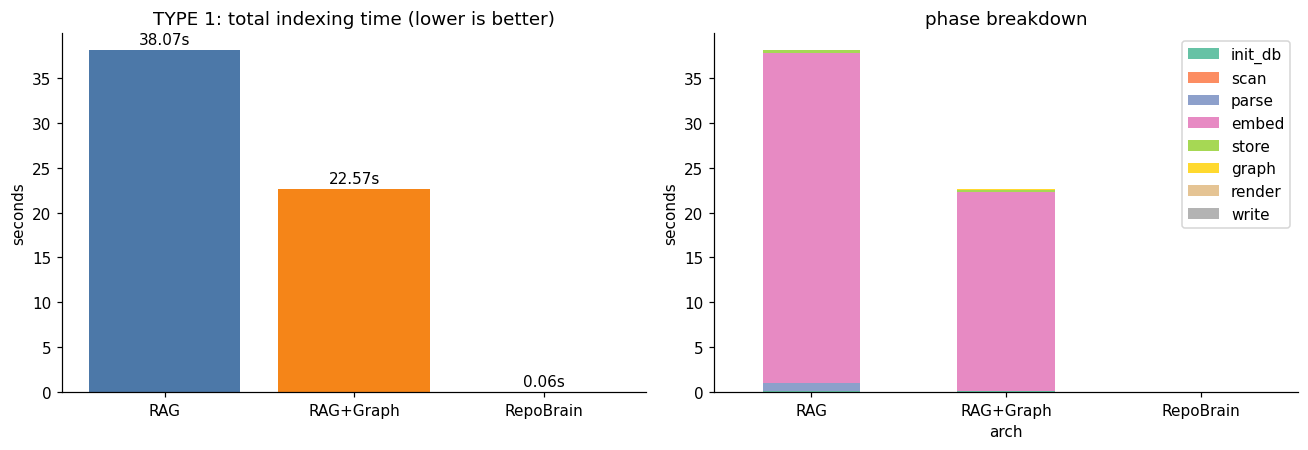

,total_s,n_files,n_chunks
arch,,,
RAG,38.067,19,243
RAG+Graph,22.575,19,243
RepoBrain,0.057,19,243


In [12]:
#TYPE 1
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"RAG": "#4C78A8", "RAG+Graph": "#F58518", "RepoBrain": "#54A24B"}

_wd = WORK / f"warmup_{RUN_ID}"; (_wd / "r").mkdir(parents=True, exist_ok=True); (_wd / "r" / "w.py").write_text("def w(x):\n    return x\n")
_s = RagStore(_wd / "db", embedder, "warm"); _s.add_parses([parse_file(_wd / "r", "w.py")]); _s.query("w", 1)
_g = CodeGraph(); _g.add_file(parse_file(_wd / "r", "w.py"))

ARCHS = {"RAG": SimpleRAG(), "RAG+Graph": GraphRAG(), "RepoBrain": RepoBrain()}
rows = []
for name, a in ARCHS.items():
    st = a.index(REPO)
    rows.append({"arch": name, **st}); log("T1", f"{name:10s} {st['total_s']:.2f}s | {st['n_files']} files | {st['n_chunks']} chunks")
df1 = pd.DataFrame(rows).set_index("arch")
df1.to_csv(RESULTS / f"type1_indexing_{RUN_ID}.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
bars = ax[0].bar(df1.index, df1["total_s"], color=[COLORS[a] for a in df1.index])
ax[0].bar_label(bars, fmt="%.2fs", padding=2); ax[0].set_ylabel("seconds"); ax[0].set_title("TYPE 1: total indexing time (lower is better)")
ph = df1[[c for c in df1.columns if c.startswith("ph_")]].fillna(0); ph.columns = [c[3:] for c in ph.columns]
ph.plot(kind="bar", stacked=True, ax=ax[1], rot=0, colormap="Set2"); ax[1].set_title("phase breakdown"); ax[1].set_ylabel("seconds")
plt.tight_layout(); plt.show()
df1[["total_s", "n_files", "n_chunks"]].round(3)

## Type 2: QA Correctness & Latency

Each question is tested across all three architectures and compared against ground truth.

- Quality: LLM judge (0–1), BLEU, ROUGE-L, and perplexity.
- Performance: Latency (excluding rate-limit waits), token usage, and tool calls.
- Resumability: Results are saved to CSV after each question. If a run crashes, resume using `RESUME_FROM`.

In [13]:
# TYPE 2
QA_FILE = RESULTS / f"qa_results_{RUN_ID}.csv"
done, qa_rows = set(), []
if RESUME_FROM and Path(RESUME_FROM).exists():
    prev = pd.read_csv(RESUME_FROM); qa_rows = prev.to_dict("records"); done = {(r["qid"], r["arch"]) for r in qa_rows}
    log("INFO", f"resume: {len(done)} results already done")

for d in DATASET:
    for name, a in ARCHS.items():
        if (d["id"], name) in done: continue
        r = a.ask(d["question"])
        jscore, reason = llm_judge(d["question"], d["truth"], r["answer"])
        row = {"qid": d["id"], "category": d["category"], "arch": name, "question": d["question"], "truth": d["truth"],
               "answer": r["answer"], "judge": jscore, "judge_reason": reason, "bleu": bleu(d["truth"], r["answer"]),
               "rouge_l": rouge_l(d["truth"], r["answer"]), "perplexity": perplexity(r["answer"]),
               **{k: r[k] for k in ["latency_s", "wall_s", "wait_s", "llm_calls", "tool_calls", "tokens_in", "tokens_out", "retries", "error"]},
               "tools_used": ",".join(r["tools_used"])}
        qa_rows.append(row); pd.DataFrame(qa_rows).to_csv(QA_FILE, index=False)
        log("T2", f"{d['id']} {name:10s} judge={jscore:.1f} rougeL={row['rouge_l']:.2f} net={r['latency_s']:.1f}s "
                  f"(wait {r['wait_s']:.0f}s) tools={r['tool_calls']} retries={r['retries']} {('ERR ' + r['error'][:60]) if r['error'] else ''}")
df2 = pd.DataFrame(qa_rows)
print("saved ->", QA_FILE)

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


[T2] q01 RAG        judge=0.5 rougeL=0.34 net=0.9s (wait 0s) tools=0 retries=0 
[TPM] QA: ~4479+3291 > 6000; rukna padega (latency me count nahi hoga)
[T2] q01 RAG+Graph  judge=0.0 rougeL=0.00 net=2.6s (wait 60s) tools=0 retries=0 ERR BadRequestError: Error code: 400 - {'error': {'message': "Pa
[TPM] QA: ~2757+6282 > 6000; rukna padega (latency me count nahi hoga)
[TPM] QA: ~5273+6558 > 6000; rukna padega (latency me count nahi hoga)
[T2] q01 RepoBrain  judge=1.0 rougeL=0.49 net=2.1s (wait 120s) tools=2 retries=0 
[TPM] QA: ~5567+2724 > 6000; rukna padega (latency me count nahi hoga)
[T2] q02 RAG        judge=1.0 rougeL=0.26 net=0.7s (wait 59s) tools=0 retries=0 
[T2] q02 RAG+Graph  judge=1.0 rougeL=0.38 net=1.1s (wait 0s) tools=1 retries=0 
[TPM] QA: ~3796+6289 > 6000; rukna padega (latency me count nahi hoga)
[TPM] QA: ~5232+8032 > 6000; rukna padega (latency me count nahi hoga)
[T2] q02 RepoBrain  judge=1.0 rougeL=0.32 net=2.2s (wait 120s) tools=2 retries=0 
[TPM] QA: ~6913+2762 > 6

,judge,rouge_l,bleu,perplexity,latency_s,wait_s,tokens_in,tokens_out,llm_calls,tool_calls,retries,errors
arch,,,,,,,,,,,,
RAG,0.386,0.191,0.044,44.706,0.571,29.619,706.000,121.214,1.0,0.000,0,4
RAG+Graph,0.429,0.142,0.029,42.810,8.919,46.574,1973.000,113.643,1.5,1.071,0,8
RepoBrain,0.500,0.195,0.056,56.079,1.236,77.263,5774.714,102.143,1.5,1.000,0,7


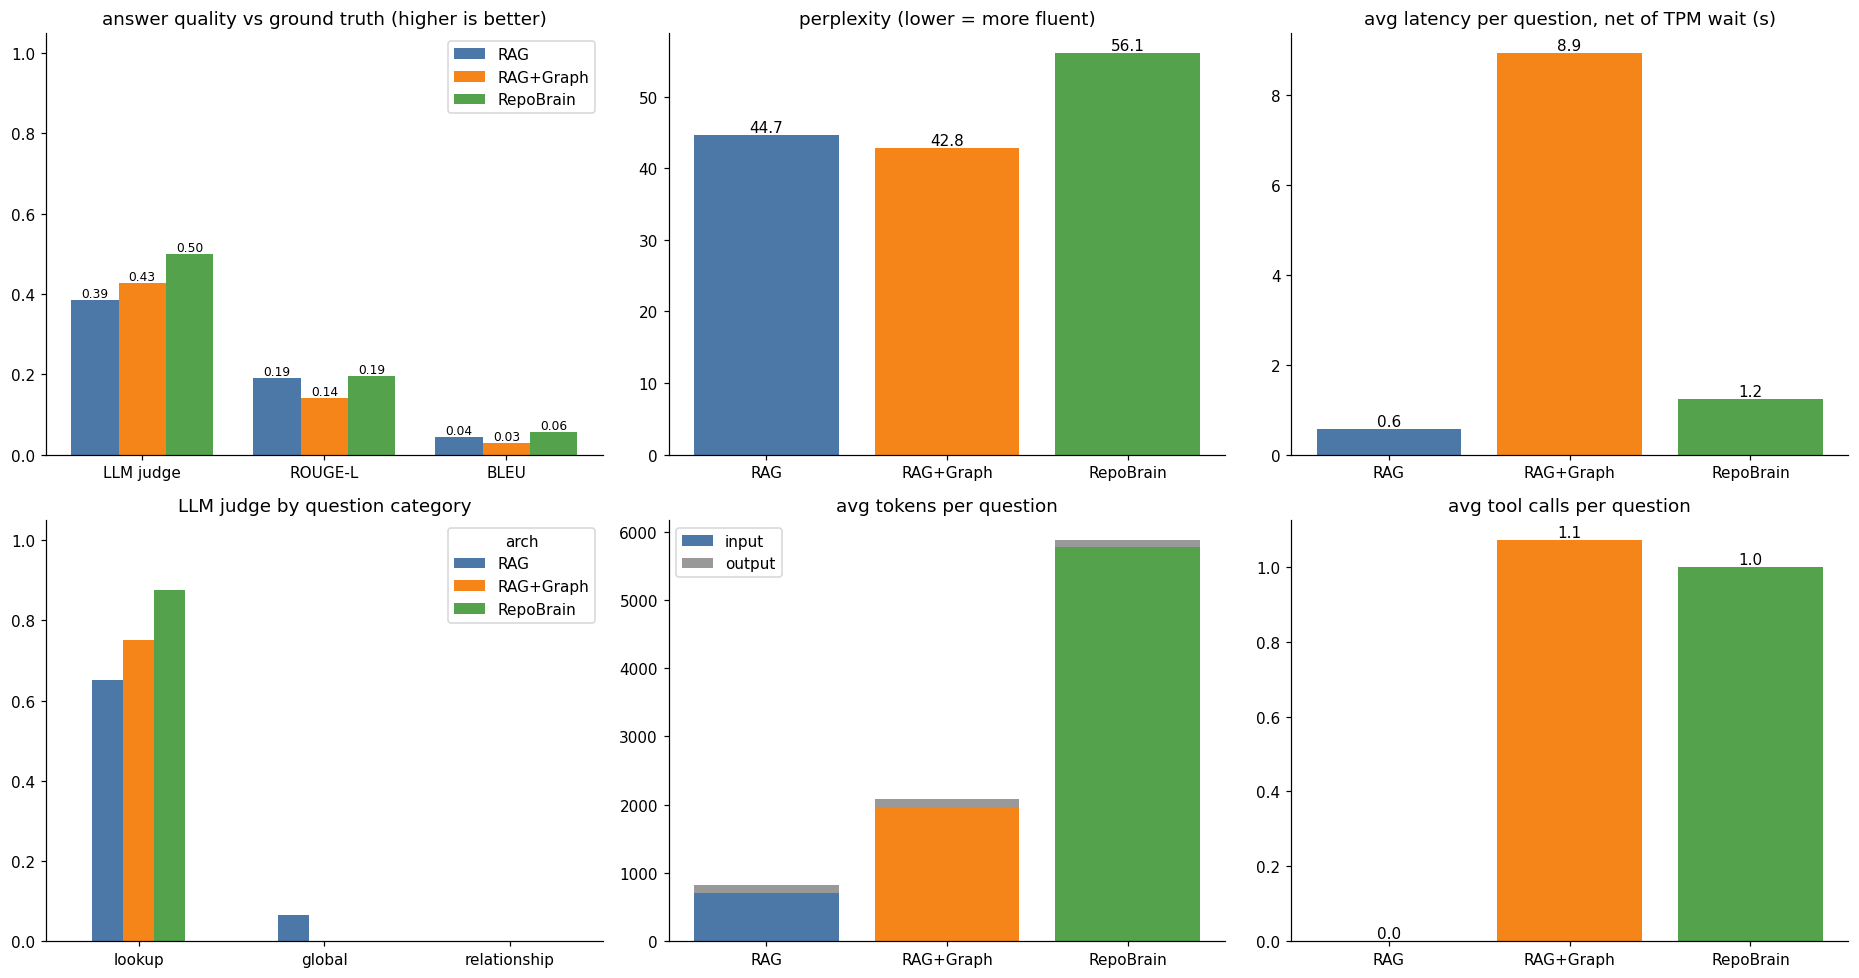

arch,RAG,RAG+Graph,RepoBrain
qid,,,
q01,0.5,0.0,1.0
q02,1.0,1.0,1.0
q03,0.7,1.0,0.0
q04,1.0,1.0,1.0
q05,0.0,1.0,1.0
q06,0.0,0.0,1.0
q07,1.0,1.0,1.0
q08,1.0,1.0,1.0
q09,0.1,0.0,0.0


In [14]:
# TYPE 2: summary table + graphs
agg = df2.groupby("arch").agg(judge=("judge", "mean"), rouge_l=("rouge_l", "mean"), bleu=("bleu", "mean"),
                              perplexity=("perplexity", "mean"), latency_s=("latency_s", "mean"), wait_s=("wait_s", "mean"),
                              tokens_in=("tokens_in", "mean"), tokens_out=("tokens_out", "mean"),
                              llm_calls=("llm_calls", "mean"), tool_calls=("tool_calls", "mean"),
                              retries=("retries", "sum"), errors=("error", lambda s: s.notna().sum())).reindex(list(ARCHS))
display(agg.round(3))
agg.round(4).to_csv(RESULTS / f"type2_summary_{RUN_ID}.csv")

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
x, w = np.arange(3), 0.26
for i, a in enumerate(agg.index):
    vals = [agg.loc[a, "judge"], agg.loc[a, "rouge_l"], agg.loc[a, "bleu"]]
    b = ax[0, 0].bar(x + (i - 1) * w, vals, w, label=a, color=COLORS[a]); ax[0, 0].bar_label(b, fmt="%.2f", fontsize=8)
ax[0, 0].set_xticks(x); ax[0, 0].set_xticklabels(["LLM judge", "ROUGE-L", "BLEU"]); ax[0, 0].set_ylim(0, 1.05)
ax[0, 0].set_title("answer quality vs ground truth (higher is better)"); ax[0, 0].legend()

for axi, col, title, fmt in [(ax[0, 1], "perplexity", "perplexity (lower = more fluent)", "%.1f"),
                              (ax[0, 2], "latency_s", "avg latency per question, net of TPM wait (s)", "%.1f")]:
    b = axi.bar(agg.index, agg[col], color=[COLORS[a] for a in agg.index]); axi.bar_label(b, fmt=fmt); axi.set_title(title)

cat = df2.groupby(["category", "arch"])["judge"].mean().unstack().reindex(CATEGORIES)[list(ARCHS)]
cat.plot(kind="bar", ax=ax[1, 0], rot=0, color=[COLORS[a] for a in cat.columns]); ax[1, 0].set_ylim(0, 1.05)
ax[1, 0].set_title("LLM judge by question category"); ax[1, 0].set_xlabel("")

ax[1, 1].bar(agg.index, agg["tokens_in"], color=[COLORS[a] for a in agg.index], label="input")
ax[1, 1].bar(agg.index, agg["tokens_out"], bottom=agg["tokens_in"], color="#999", label="output")
ax[1, 1].set_title("avg tokens per question"); ax[1, 1].legend()
b = ax[1, 2].bar(agg.index, agg["tool_calls"], color=[COLORS[a] for a in agg.index]); ax[1, 2].bar_label(b, fmt="%.1f"); ax[1, 2].set_title("avg tool calls per question")
plt.tight_layout(); plt.show()

per_q = df2.pivot(index="qid", columns="arch", values="judge")[list(ARCHS)]
display(per_q.round(2))

## Type 3: Incremental Update

Three changes are applied sequentially to `src/requests/utils.py`: add a function → modify a function (shifting line numbers) → delete a function.

Each change is applied to disk once, then all three architectures update their indexes. Only the `update()` call is timed.

After each update, `verify()` (untimed) checks whether the incremental index matches a fresh rebuild. Baseline: Full re-indexing time from Type 1.

[T3] add_function     RAG          5493.7 ms  (-41/+42 chunks)  consistent=True
[T3] add_function     RAG+Graph    5148.0 ms  (-41/+42 chunks)  consistent=True
[T3] add_function     RepoBrain      11.6 ms  (-1/+1 chunks)  consistent=True
[T3] modify_function  RAG          4631.2 ms  (-42/+42 chunks)  consistent=True
[T3] modify_function  RAG+Graph    5868.1 ms  (-42/+42 chunks)  consistent=True
[T3] modify_function  RepoBrain      11.3 ms  (-1/+1 chunks)  consistent=True
[T3] delete_function  RAG          4618.6 ms  (-42/+41 chunks)  consistent=True
[T3] delete_function  RAG+Graph    5139.3 ms  (-42/+41 chunks)  consistent=True
[T3] delete_function  RepoBrain      19.6 ms  (-1/+1 chunks)  consistent=True


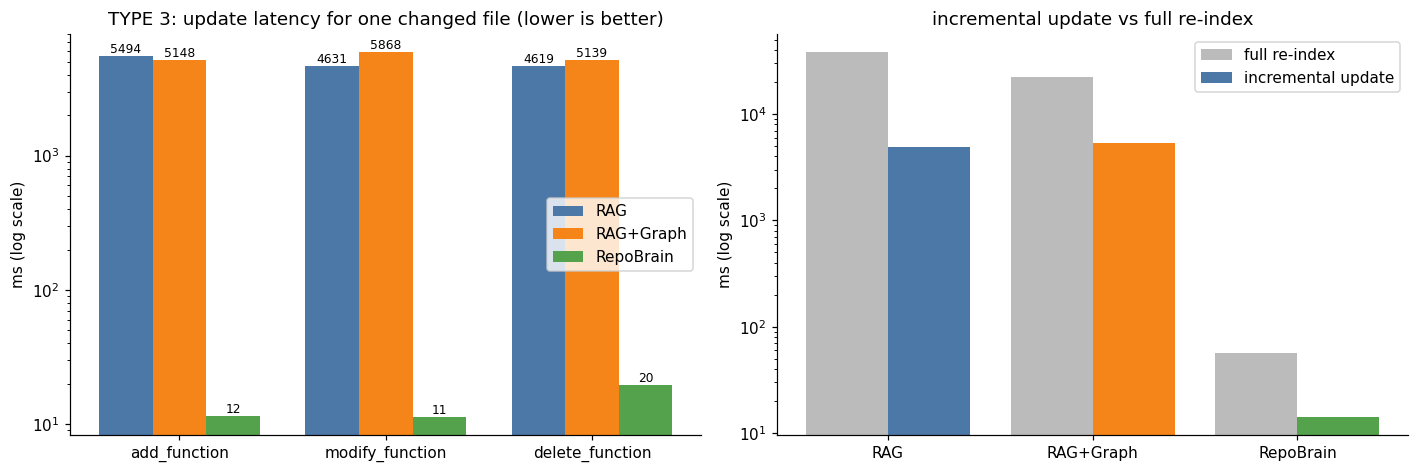

,mutation,arch,update_s,chunks_removed,chunks_added,speedup_vs_full,consistent
0,add_function,RAG,5.4937,41,42,6.9292,True
1,add_function,RAG+Graph,5.1480,41,42,4.3852,True
2,add_function,RepoBrain,0.0116,1,1,4.9083,True
3,modify_function,RAG,4.6312,42,42,8.2198,True
4,modify_function,RAG+Graph,5.8681,42,42,3.8470,True
5,modify_function,RepoBrain,0.0113,1,1,5.0211,True
6,delete_function,RAG,4.6186,42,41,8.2422,True
7,delete_function,RAG+Graph,5.1393,42,41,4.3926,True
8,delete_function,RepoBrain,0.0196,1,1,2.9122,True


In [15]:
#TYPE 3
TARGET = "src/requests/utils.py"

def _rw(rel, text=None):
    p = REPO / rel
    if text is None:
        with open(p, encoding="utf-8", newline="") as f: return f.read().splitlines(keepends=True)
    with open(p, "w", encoding="utf-8", newline="") as f: f.write("".join(text))

def fn_lines(rel, name):
    s = next(s for s in parse_file(REPO, rel).symbols if s.kind == "function" and s.name == name)
    return s.start_line, s.end_line

def mutate(kind):
    lines = _rw(TARGET)
    if kind == "add_function":
        if lines and not lines[-1].endswith("\n"): lines[-1] += "\n"
        lines += ["\n\n", "def bench_added_function(x):\n", '    """Function added by the benchmark."""\n', "    return x + 1\n"]
    elif kind == "modify_function":
        s, _ = fn_lines(TARGET, "default_user_agent")
        lines[s - 1:s - 1] = [f"# benchmark edit line {k}\n" for k in range(3)]       # content badla + neeche ki sab line numbers shift
    elif kind == "delete_function":
        s, e = fn_lines(TARGET, "default_headers"); del lines[s - 1:e]
    _rw(TARGET, lines)

MUTATIONS = ["add_function", "modify_function", "delete_function"]
rows3 = []
for kind in MUTATIONS:
    mutate(kind)
    for name, a in ARCHS.items():
        st = a.update(TARGET)
        ok = a.verify()
        rows3.append({"mutation": kind, "arch": name, "update_s": st["total_s"], "chunks_removed": st["chunks_removed"],
                      "chunks_added": st["chunks_added"], "consistent": ok, "full_reindex_s": df1.loc[name, "total_s"],
                      **{k: v for k, v in st.items() if k.startswith("ph_")}})
        log("T3", f"{kind:16s} {name:10s} {st['total_s']*1000:8.1f} ms  (-{st['chunks_removed']}/+{st['chunks_added']} chunks)  consistent={ok}")
df3 = pd.DataFrame(rows3); df3["speedup_vs_full"] = df3["full_reindex_s"] / df3["update_s"]
df3.to_csv(RESULTS / f"type3_updates_{RUN_ID}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
x, w = np.arange(len(MUTATIONS)), 0.26
for i, a in enumerate(ARCHS):
    v = [df3[(df3.arch == a) & (df3.mutation == m)]["update_s"].iloc[0] * 1000 for m in MUTATIONS]
    b = ax[0].bar(x + (i - 1) * w, v, w, label=a, color=COLORS[a]); ax[0].bar_label(b, fmt="%.0f", fontsize=8)
ax[0].set_xticks(x); ax[0].set_xticklabels(MUTATIONS); ax[0].set_ylabel("ms (log scale)"); ax[0].set_yscale("log")
ax[0].set_title("TYPE 3: update latency for one changed file (lower is better)"); ax[0].legend()
m = df3.groupby("arch")[["update_s", "full_reindex_s"]].mean().reindex(list(ARCHS)) * 1000
xx = np.arange(len(m)); ax[1].bar(xx - 0.2, m["full_reindex_s"], 0.4, label="full re-index", color="#bbb")
ax[1].bar(xx + 0.2, m["update_s"], 0.4, label="incremental update", color=[COLORS[a] for a in m.index])
ax[1].set_xticks(xx); ax[1].set_xticklabels(m.index); ax[1].set_yscale("log"); ax[1].set_ylabel("ms (log scale)")
ax[1].set_title("incremental update vs full re-index"); ax[1].legend()
plt.tight_layout(); plt.show()
display(df3[["mutation", "arch", "update_s", "chunks_removed", "chunks_added", "speedup_vs_full", "consistent"]].round(4))

In [16]:
# final summary
summary = {
  "repo": f"{REPO_URL}@{REPO_TAG}", "qa_model": QA_MODEL, "judge_model": JUDGE_MODEL, "embedding_model": EMBED_MODEL,
  "type1_index_seconds": df1["total_s"].round(3).to_dict(),
  "type2_mean_judge": agg["judge"].round(3).to_dict(), "type2_mean_rouge_l": agg["rouge_l"].round(3).to_dict(),
  "type2_mean_latency_s": agg["latency_s"].round(2).to_dict(),
  "type3_mean_update_ms": (df3.groupby("arch")["update_s"].mean() * 1000).round(1).to_dict(),
  "type3_all_consistent": bool(df3["consistent"].all()),
}
(RESULTS / f"summary_{RUN_ID}.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2)); print("\nfiles in", RESULTS.resolve())

{
  "repo": "https://github.com/psf/requests@v2.32.3",
  "qa_model": "openai/gpt-oss-120b",
  "judge_model": "openai/gpt-oss-120b",
  "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
  "type1_index_seconds": {
    "RAG": 38.067,
    "RAG+Graph": 22.575,
    "RepoBrain": 0.057
  },
  "type2_mean_judge": {
    "RAG": 0.386,
    "RAG+Graph": 0.429,
    "RepoBrain": 0.5
  },
  "type2_mean_rouge_l": {
    "RAG": 0.191,
    "RAG+Graph": 0.142,
    "RepoBrain": 0.195
  },
  "type2_mean_latency_s": {
    "RAG": 0.57,
    "RAG+Graph": 8.92,
    "RepoBrain": 1.24
  },
  "type3_mean_update_ms": {
    "RAG": 4914.5,
    "RAG+Graph": 5385.1,
    "RepoBrain": 14.2
  },
  "type3_all_consistent": true
}

files in /content/results
